In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

In [2]:
# Φόρτωση .mat αρχείου
data = loadmat('tiger.mat')
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'tiger'])


Διαστάσεις: (256, 256)
Min: 0.0
Max: 1.0


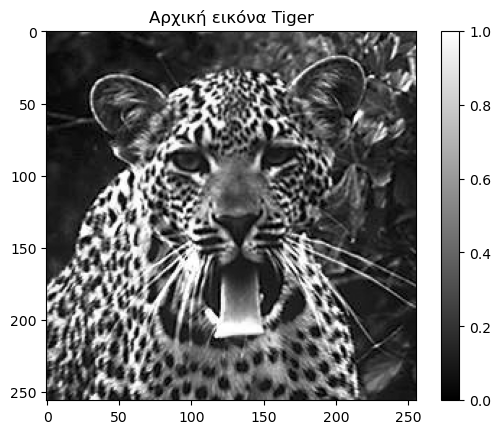

In [3]:
# Εξαγωγή εικόνας
img = data['tiger'].astype(float)

print(f"Διαστάσεις: {img.shape}")
print(f"Min: {img.min()}")
print(f"Max: {img.max()}")

plt.imshow(img, cmap='gray')
plt.title('Αρχική εικόνα Tiger')
plt.colorbar()
plt.show()

Διασπορά σήματος: 0.070731
Διασπορά θορύβου: 0.002237


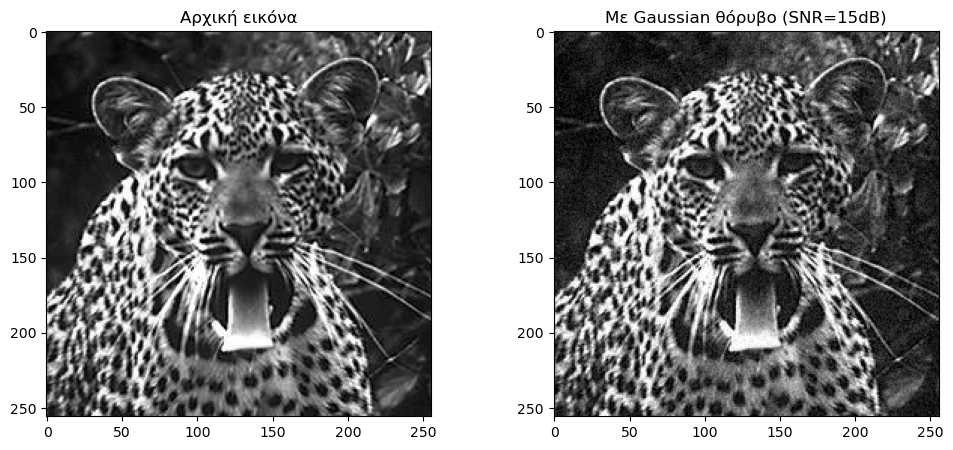

In [4]:
# Προσθήκη Gaussian θορύβου με SNR=15dB
SNR_db = 15
sigma_signal = img.std()
sigma_noise = sigma_signal / np.sqrt(10 ** (SNR_db / 10))

print(f"Διασπορά σήματος: {sigma_signal**2:.6f}")
print(f"Διασπορά θορύβου: {sigma_noise**2:.6f}")

# Δημιουργία θορύβου
noise = np.random.normal(0, sigma_noise, img.shape)

# Προσθήκη στην εικόνα
img_noisy = img + noise
img_noisy = np.clip(img_noisy, 0, 1)

# Εμφάνιση
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Αρχική εικόνα')
axes[1].imshow(img_noisy, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Με Gaussian θόρυβο (SNR=15dB)')
plt.show()

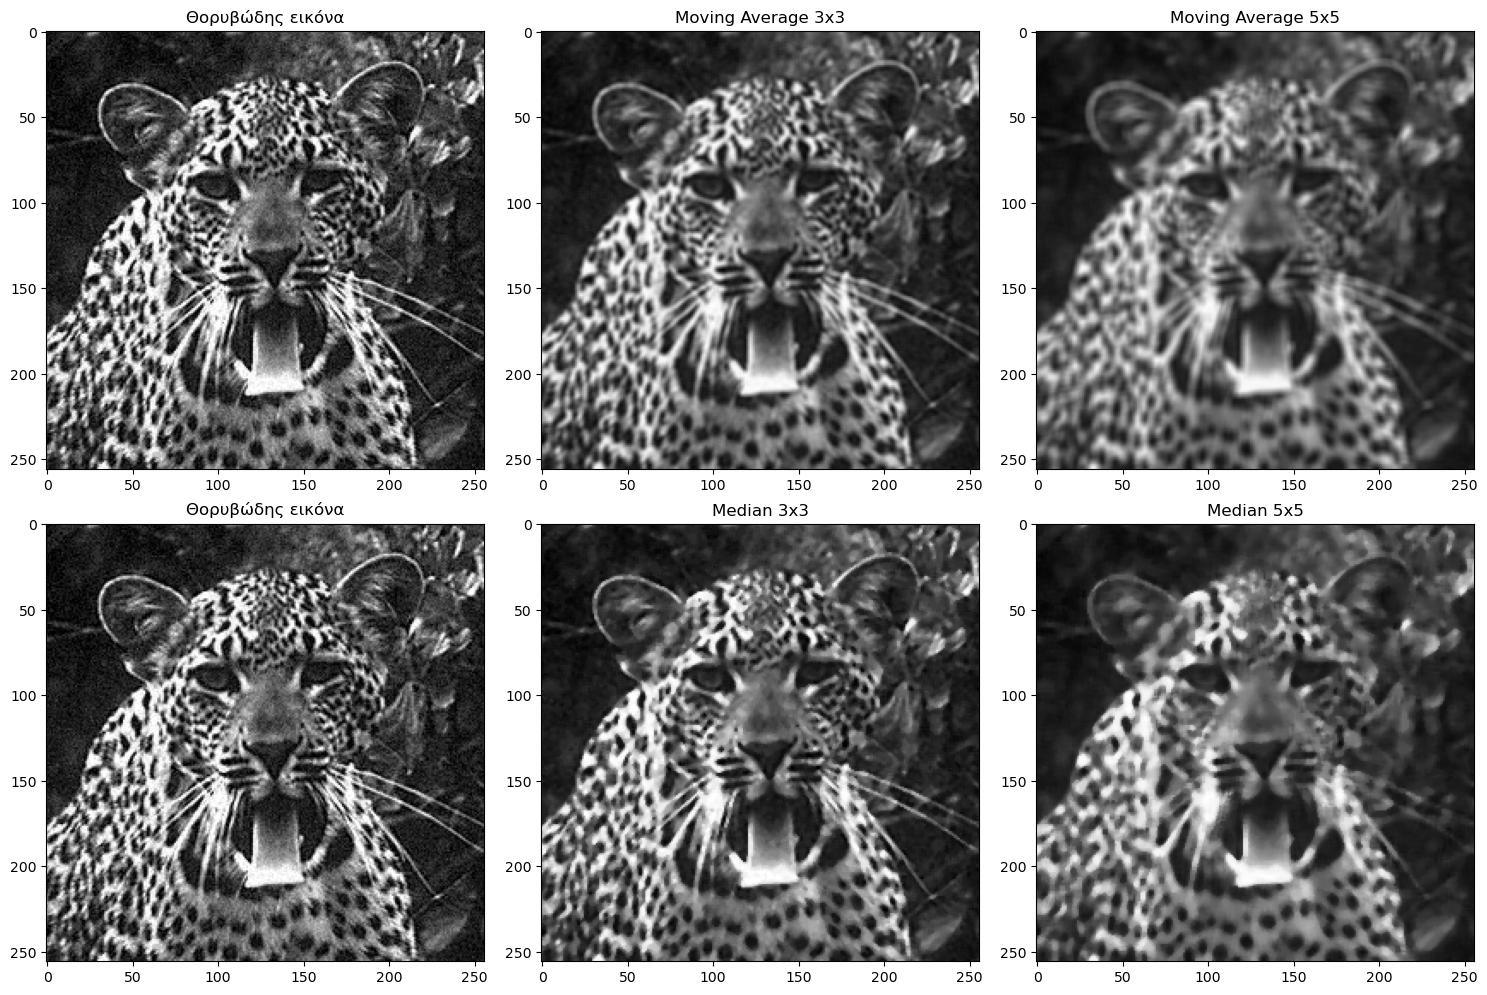

In [5]:
from scipy.ndimage import uniform_filter, median_filter

# Moving Average
ma_3x3 = uniform_filter(img_noisy, size=3)
ma_5x5 = uniform_filter(img_noisy, size=5)

# Median
med_3x3 = median_filter(img_noisy, size=3)
med_5x5 = median_filter(img_noisy, size=5)

# Εμφάνιση
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0,0].imshow(img_noisy, cmap='gray', vmin=0, vmax=1)
axes[0,0].set_title('Θορυβώδης εικόνα')

axes[0,1].imshow(ma_3x3, cmap='gray', vmin=0, vmax=1)
axes[0,1].set_title('Moving Average 3x3')

axes[0,2].imshow(ma_5x5, cmap='gray', vmin=0, vmax=1)
axes[0,2].set_title('Moving Average 5x5')

axes[1,0].imshow(img_noisy, cmap='gray', vmin=0, vmax=1)
axes[1,0].set_title('Θορυβώδης εικόνα')

axes[1,1].imshow(med_3x3, cmap='gray', vmin=0, vmax=1)
axes[1,1].set_title('Median 3x3')

axes[1,2].imshow(med_5x5, cmap='gray', vmin=0, vmax=1)
axes[1,2].set_title('Median 5x5')

plt.tight_layout()
plt.show()

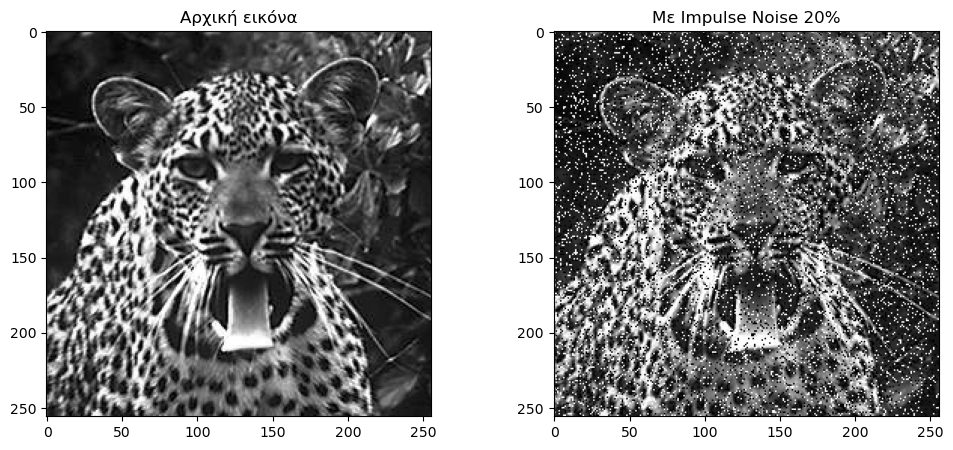

In [6]:
# Προσθήκη impulse noise 20%
img_impulse = img.copy()
M, N = img.shape

# Τυχαία επιλογή 20% pixels
num_pixels = int(0.20 * M * N)

# Salt (άσπρα pixels)
coords = [np.random.randint(0, M, num_pixels//2), 
          np.random.randint(0, N, num_pixels//2)]
img_impulse[coords[0], coords[1]] = 1

# Pepper (μαύρα pixels)
coords = [np.random.randint(0, M, num_pixels//2), 
          np.random.randint(0, N, num_pixels//2)]
img_impulse[coords[0], coords[1]] = 0

# Εμφάνιση
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Αρχική εικόνα')
axes[1].imshow(img_impulse, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Με Impulse Noise 20%')
plt.show()

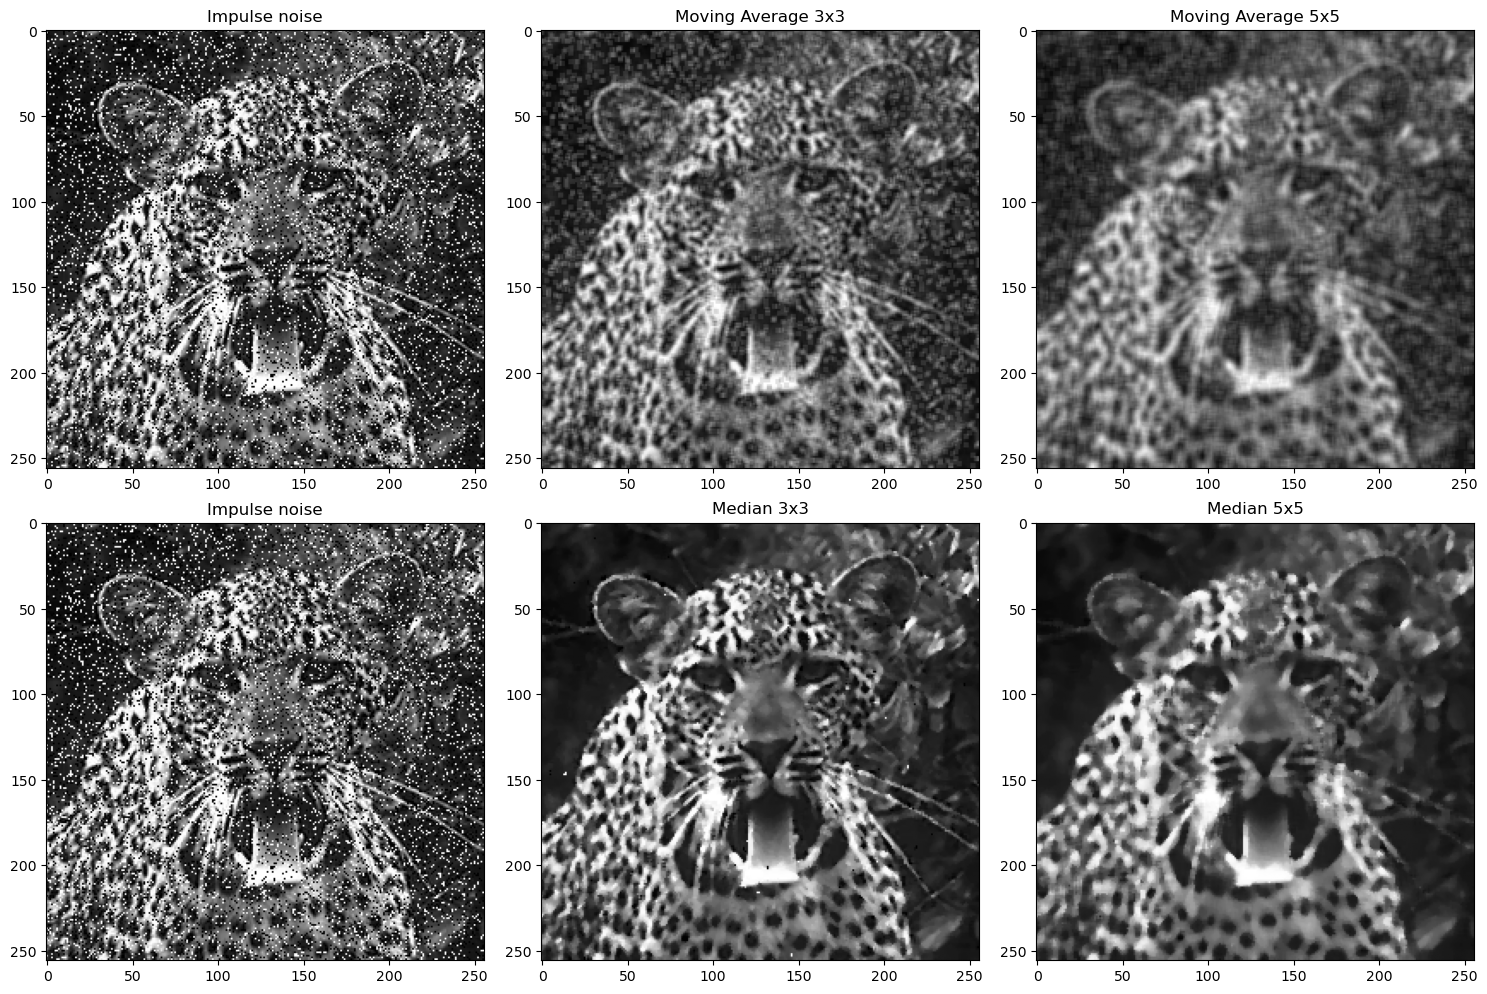

In [7]:
# Εφαρμογή φίλτρων στην εικόνα με impulse noise
ma_3x3_imp = uniform_filter(img_impulse, size=3)
ma_5x5_imp = uniform_filter(img_impulse, size=5)
med_3x3_imp = median_filter(img_impulse, size=3)
med_5x5_imp = median_filter(img_impulse, size=5)

# Εμφάνιση
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0,0].imshow(img_impulse, cmap='gray', vmin=0, vmax=1)
axes[0,0].set_title('Impulse noise')
axes[0,1].imshow(ma_3x3_imp, cmap='gray', vmin=0, vmax=1)
axes[0,1].set_title('Moving Average 3x3')
axes[0,2].imshow(ma_5x5_imp, cmap='gray', vmin=0, vmax=1)
axes[0,2].set_title('Moving Average 5x5')

axes[1,0].imshow(img_impulse, cmap='gray', vmin=0, vmax=1)
axes[1,0].set_title('Impulse noise')
axes[1,1].imshow(med_3x3_imp, cmap='gray', vmin=0, vmax=1)
axes[1,1].set_title('Median 3x3')
axes[1,2].imshow(med_5x5_imp, cmap='gray', vmin=0, vmax=1)
axes[1,2].set_title('Median 5x5')

plt.tight_layout()
plt.show()

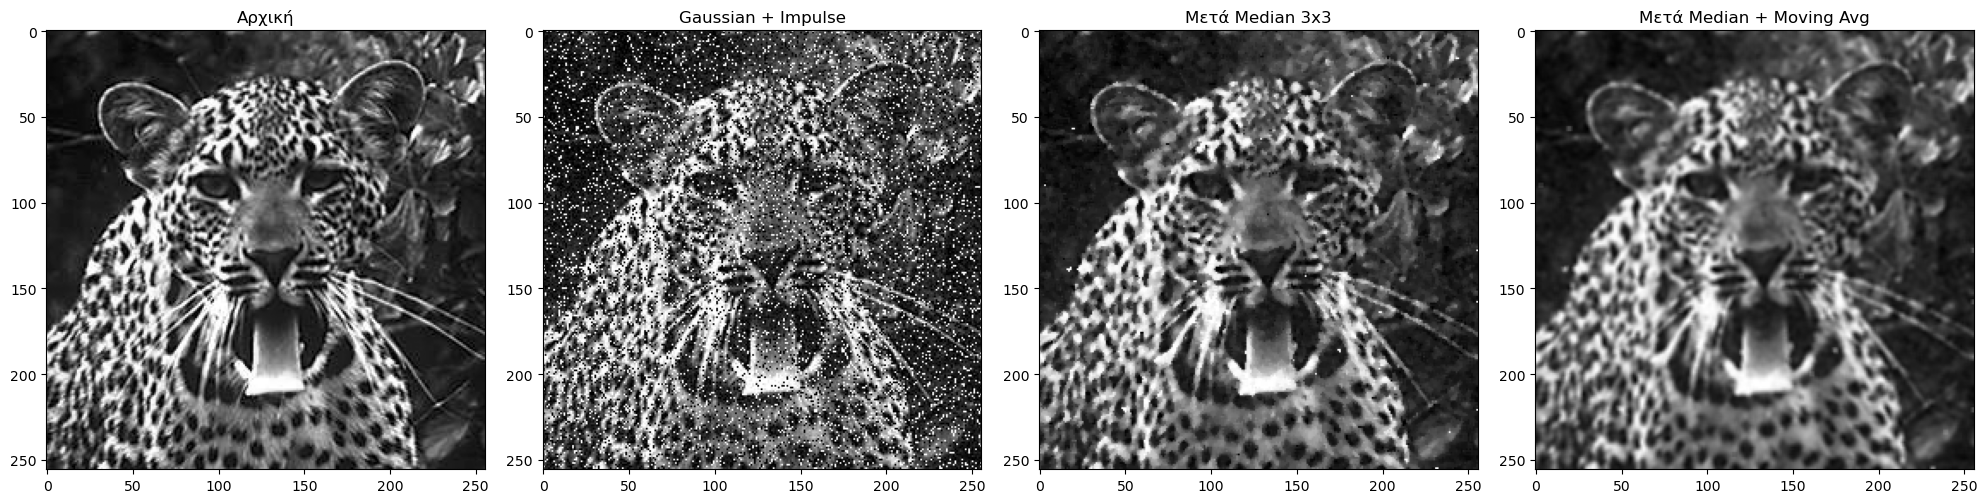

In [9]:
# Προσθήκη και των δύο θορύβων στην αρχική εικόνα
img_both = img.copy()
M, N = img.shape

# Υπολογισμός noise_power
signal_power = np.var(img)
SNR_dB = 15
SNR_linear = 10 ** (SNR_dB / 10)
noise_power = signal_power / SNR_linear

# Gaussian θόρυβος SNR=15dB
img_both = img_both + np.random.normal(0, np.sqrt(noise_power), img.shape)

# Impulse noise 20%
num_pixels = int(0.20 * M * N)
coords = [np.random.randint(0, M, num_pixels//2),
          np.random.randint(0, N, num_pixels//2)]
img_both[coords[0], coords[1]] = 1
coords = [np.random.randint(0, M, num_pixels//2),
          np.random.randint(0, N, num_pixels//2)]
img_both[coords[0], coords[1]] = 0

# Διαδοχική εφαρμογή: πρώτα Median, μετά Moving Average
step1 = median_filter(img_both, size=3)
step2 = uniform_filter(step1, size=3)

# Εμφάνιση
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Αρχική')
axes[1].imshow(img_both, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Gaussian + Impulse')
axes[2].imshow(step1, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Μετά Median 3x3')
axes[3].imshow(step2, cmap='gray', vmin=0, vmax=1)
axes[3].set_title('Μετά Median + Moving Avg')
plt.tight_layout()
plt.show()

In [10]:
def calculate_psnr(original, filtered):
    mse = np.mean((original - filtered) ** 2)
    if mse == 0:
        return float('inf')
    psnr = 10 * np.log10(1.0 / mse)
    return psnr, mse

# PSNR για Gaussian θόρυβο
psnr_gauss, mse_gauss = calculate_psnr(img, img_noisy)
psnr_ma3, mse_ma3 = calculate_psnr(img, ma_3x3)
psnr_ma5, mse_ma5 = calculate_psnr(img, ma_5x5)
psnr_med3, mse_med3 = calculate_psnr(img, med_3x3)
psnr_med5, mse_med5 = calculate_psnr(img, med_5x5)

print("=== Gaussian Θόρυβος ===")
print(f"Θορυβώδης εικόνα  : PSNR={psnr_gauss:.2f}dB, MSE={mse_gauss:.6f}")
print(f"Moving Average 3x3: PSNR={psnr_ma3:.2f}dB, MSE={mse_ma3:.6f}")
print(f"Moving Average 5x5: PSNR={psnr_ma5:.2f}dB, MSE={mse_ma5:.6f}")
print(f"Median 3x3        : PSNR={psnr_med3:.2f}dB, MSE={mse_med3:.6f}")
print(f"Median 5x5        : PSNR={psnr_med5:.2f}dB, MSE={mse_med5:.6f}")

# PSNR για Impulse θόρυβο
psnr_imp, mse_imp = calculate_psnr(img, img_impulse)
psnr_ma3_imp, mse_ma3_imp = calculate_psnr(img, ma_3x3_imp)
psnr_med3_imp, mse_med3_imp = calculate_psnr(img, med_3x3_imp)

print("\n=== Impulse Θόρυβος ===")
print(f"Θορυβώδης εικόνα  : PSNR={psnr_imp:.2f}dB, MSE={mse_imp:.6f}")
print(f"Moving Average 3x3: PSNR={psnr_ma3_imp:.2f}dB, MSE={mse_ma3_imp:.6f}")
print(f"Median 3x3        : PSNR={psnr_med3_imp:.2f}dB, MSE={mse_med3_imp:.6f}")

=== Gaussian Θόρυβος ===
Θορυβώδης εικόνα  : PSNR=26.72dB, MSE=0.002129
Moving Average 3x3: PSNR=22.12dB, MSE=0.006133
Moving Average 5x5: PSNR=17.67dB, MSE=0.017096
Median 3x3        : PSNR=23.06dB, MSE=0.004943
Median 5x5        : PSNR=18.25dB, MSE=0.014978

=== Impulse Θόρυβος ===
Θορυβώδης εικόνα  : PSNR=12.18dB, MSE=0.060573
Moving Average 3x3: PSNR=17.81dB, MSE=0.016552
Median 3x3        : PSNR=21.13dB, MSE=0.007717


Για τον Gaussian θόρυβο, τα αποτελέσματα PSNR έδειξαν ότι η θορυβώδης εικόνα (26.72dB) είχε υψηλότερο PSNR από τις φιλτραρισμένες, γεγονός που δείχνει ότι το θόλωμα που εισάγουν τα φίλτρα επιδεινώνει την ποιότητα για αυτό τον τύπο θορύβου. Το Moving Average 3×3 (22.12dB) και το Median 3×3 (23.06dB) δίνουν παρόμοια αποτελέσματα, με ελαφρά υπεροχή του Median στη διατήρηση ακμών. Για τον impulse θόρυβο αντίθετα, το Median φίλτρο αναδεικνύεται σαφώς ανώτερο, επιτυγχάνει PSNR 21.13dB έναντι 17.81dB του Moving Average, καθώς η διάμεσος αγνοεί φυσικά τις ακραίες τιμές (0 και 1) χωρίς να τις "απλώνει" στη γειτονιά όπως κάνει ο μέσος όρος. Οπτικά, αυτό επιβεβαιώνεται από τα αποτελέσματα: το Median αφαιρεί σχεδόν τελείως τα άσπρα/μαύρα pixels του impulse noise διατηρώντας τις λεπτομέρειες της εικόνας, ενώ το Moving Average τα "θολώνει" χωρίς να τα εξαλείφει. Για συνδυασμό και των δύο θορύβων, η βέλτιστη στρατηγική είναι η διαδοχική εφαρμογή: πρώτα Median για αφαίρεση του impulse noise και στη συνέχεια Moving Average για εξομάλυνση του Gaussian.